# RISE Internship - Machine Learning & AI
## Project 1: Industry-Oriented Machine Learning System for Customer Churn Prediction

---

### **Executive Overview**
Customer churn represents the rate at which customers discontinue their relationship with a service provider. In the telecommunications and subscription-based service sectors, acquiring new customers costs between **5x to 7x more** than retaining existing ones. 

This notebook delivers an end-to-end industry-ready Machine Learning system that:
1. Ingests and cleans customer demographic, billing, and subscription data.
2. Performs comprehensive Exploratory Data Analysis (EDA) to identify key churn drivers.
3. Implements feature engineering, one-hot encoding, and numerical scaling.
4. Trains, tunes, and evaluates multiple predictive models (**Logistic Regression**, **Random Forest**, and **Gradient Boosting**).
5. Prioritizes **Recall** to minimize costly False Negatives and deploys a **High-Risk Probability Threshold (>70%)** business logic filter for targeted retention interventions.
6. Serializes model artifacts ready for production scoring.

---
### **Tech Stack**
* **Core Language:** Python
* **Data Processing & Analytics:** NumPy, Pandas
* **Data Visualization:** Matplotlib, Seaborn
* **Machine Learning & Modeling:** Scikit-learn
* **Environment:** Jupyter Notebook

## Phase 1: Environment & Dataset Ingestion

In this phase, we import the necessary libraries, set global plotting configurations, load the customer churn dataset into a Pandas DataFrame, and inspect the initial schema and data types.

In [1]:
# Import standard data manipulation and visualization libraries
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing and metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the dataset
data_path = os.path.join('..', 'data', 'Telco-Customer-Churn.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'Telco-Customer-Churn.csv')

df = pd.read_csv(data_path)
print(f"Dataset successfully loaded. Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Dataset successfully loaded. Shape: 7,043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Dataset schema and data types inspection
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Summary statistics for initial numerical features
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## Phase 2: Data Cleaning & Exploratory Data Analysis (EDA)

### Data Cleaning
1. Notice that `TotalCharges` is stored as an `object` (string) data type rather than a float.
2. In the raw dataset, newly onboarded customers with `tenure == 0` have blank space strings (`' '`) in `TotalCharges`.
3. We convert `TotalCharges` to numeric using `pd.to_numeric` with `errors='coerce'` and impute the resulting 11 NaN values with `0.0` (matching their zero-month tenure).

In [5]:
# Identify and handle blank strings in TotalCharges
blank_count = (df['TotalCharges'].astype(str).str.strip() == '').sum()
print(f"Number of blank TotalCharges records: {blank_count}")

# Convert TotalCharges to float and impute nulls with 0.0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', np.nan), errors='coerce').fillna(0.0)

# Verify cleaning
print(f"TotalCharges converted. New data type: {df['TotalCharges'].dtype}")
print(f"Remaining null values across all columns: {df.isnull().sum().sum()}")

Number of blank TotalCharges records: 11
TotalCharges converted. New data type: float64
Remaining null values across all columns: 0


### Exploratory Data Analysis (EDA)

We explore the distributions of key features and their correlation with customer churn:
1. **Target Distribution**: Overall Churn vs Non-Churn ratio.
2. **Contract Type**: Month-to-month contracts vs 1-Year / 2-Year long-term commitments.
3. **Internet Service**: Fiber optic vs DSL vs No internet service.
4. **Tenure**: Customer lifetime length (in months) vs churn propensity.
5. **Monthly Charges & Payment Method**: Influence of billing amounts and electronic check payment.

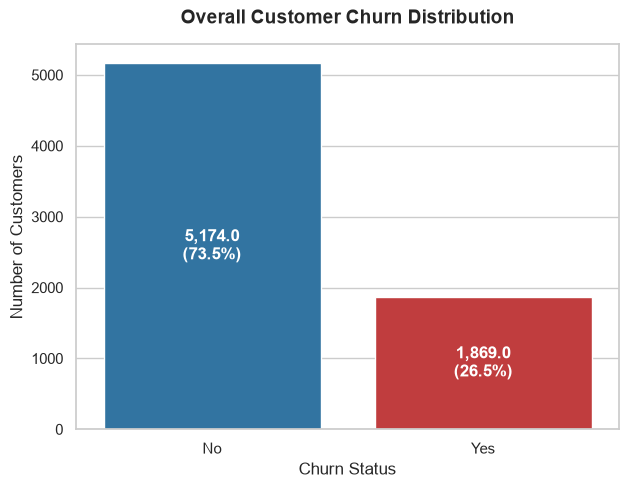

In [6]:
# 1. Overall Churn Distribution
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Churn', hue='Churn', palette=['#1f77b4', '#d62728'], legend=False)
total = len(df)
for p in ax.patches:
    height = p.get_height()
    pct = 100 * height / total
    ax.annotate(f'{height:,}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.title('Overall Customer Churn Distribution', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.show()

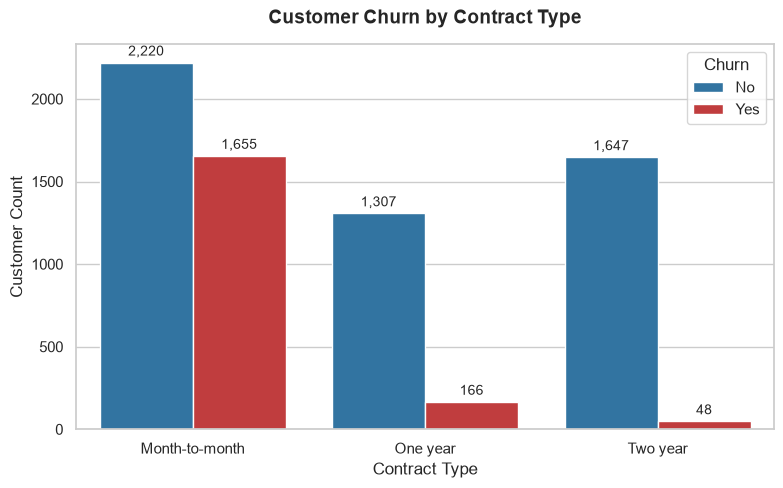

In [7]:
# 2. Churn by Contract Type
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x='Contract', hue='Churn', palette=['#1f77b4', '#d62728'])
plt.title('Customer Churn by Contract Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Contract Type', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
plt.legend(title='Churn', frameon=True)

# Add percentages on bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}', (p.get_x() + p.get_width() / 2., height + 25),
                    ha='center', va='bottom', fontsize=10)
plt.show()

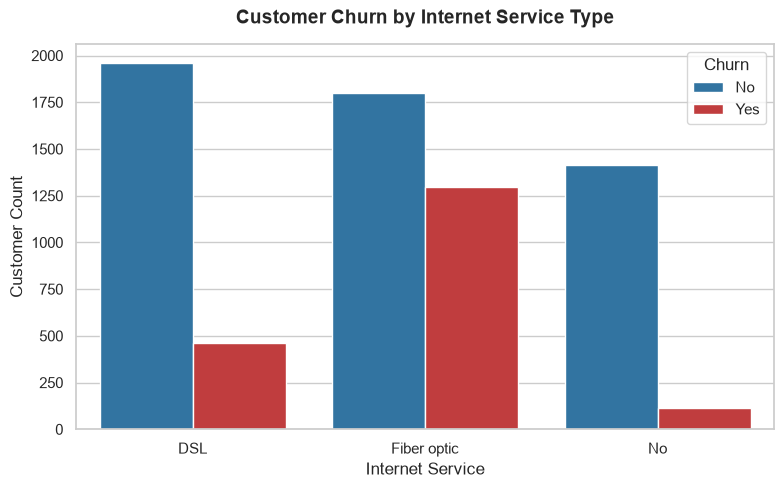

In [8]:
# 3. Churn by Internet Service Type
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x='InternetService', hue='Churn', palette=['#1f77b4', '#d62728'])
plt.title('Customer Churn by Internet Service Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Internet Service', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
plt.legend(title='Churn', frameon=True)
plt.show()

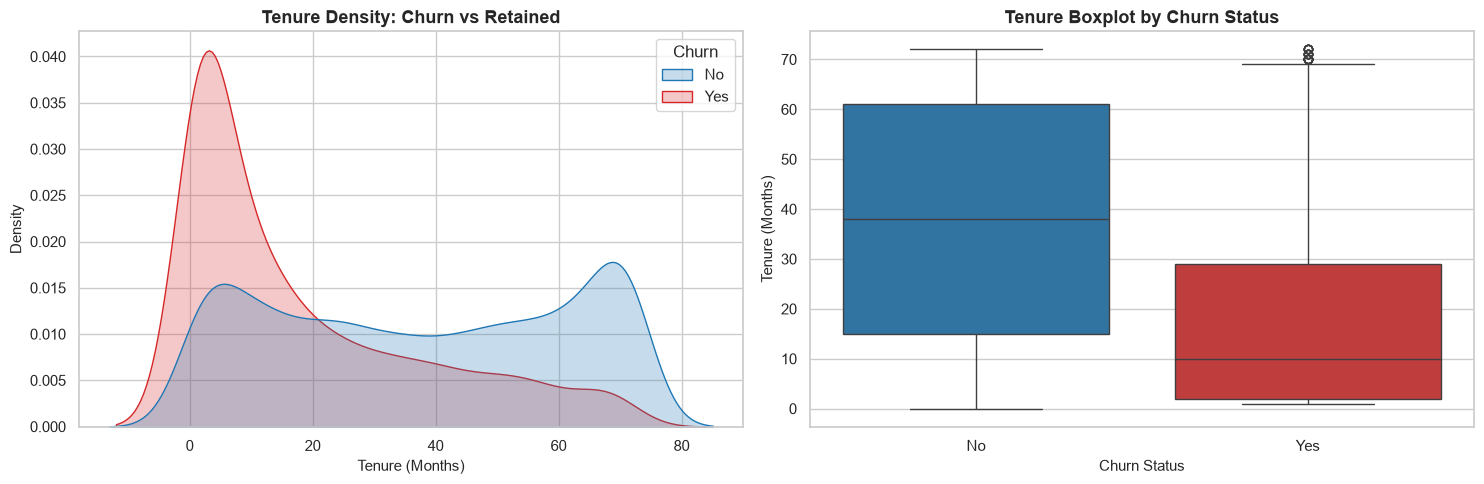

In [9]:
# 4. Tenure Distribution vs Churn
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.kdeplot(data=df, x='tenure', hue='Churn', common_norm=False, fill=True, 
            palette=['#1f77b4', '#d62728'], ax=axes[0])
axes[0].set_title('Tenure Density: Churn vs Retained', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tenure (Months)', fontsize=11)
axes[0].set_ylabel('Density', fontsize=11)

sns.boxplot(data=df, x='Churn', y='tenure', hue='Churn', 
            palette=['#1f77b4', '#d62728'], ax=axes[1], legend=False)
axes[1].set_title('Tenure Boxplot by Churn Status', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Churn Status', fontsize=11)
axes[1].set_ylabel('Tenure (Months)', fontsize=11)

plt.tight_layout()
plt.show()

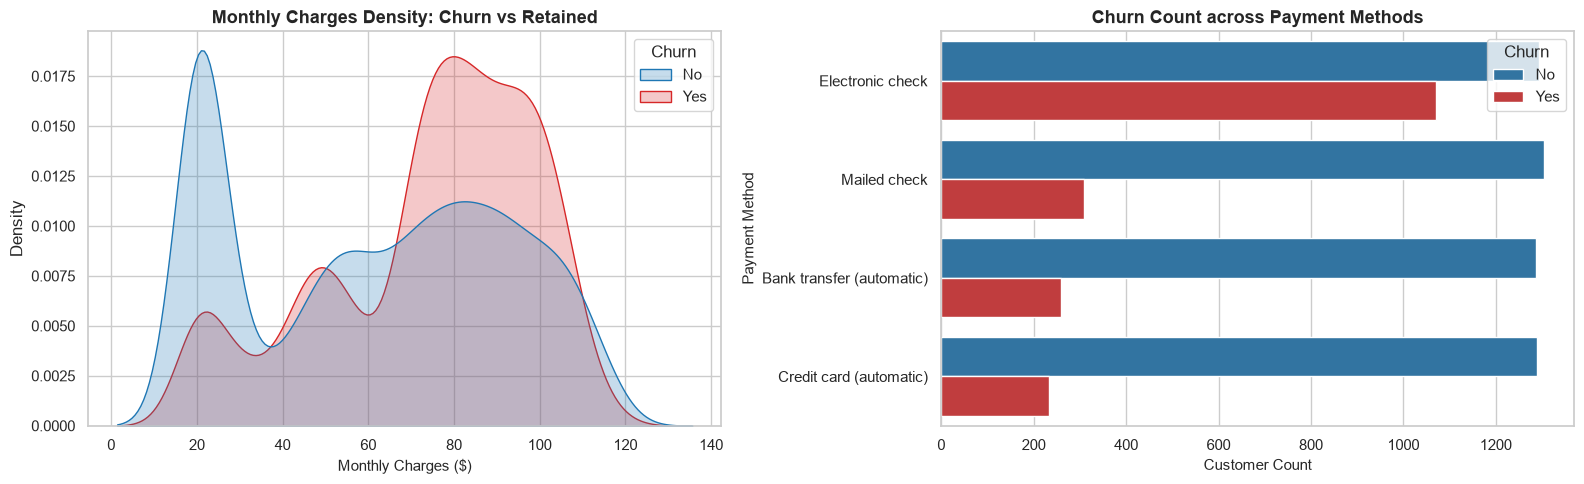

In [10]:
# 5. Monthly Charges & Payment Method Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', common_norm=False, fill=True,
            palette=['#1f77b4', '#d62728'], ax=axes[0])
axes[0].set_title('Monthly Charges Density: Churn vs Retained', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Monthly Charges ($)', fontsize=11)

sns.countplot(data=df, y='PaymentMethod', hue='Churn', palette=['#1f77b4', '#d62728'], ax=axes[1])
axes[1].set_title('Churn Count across Payment Methods', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Customer Count', fontsize=11)
axes[1].set_ylabel('Payment Method', fontsize=11)

plt.tight_layout()
plt.show()

## Phase 3: Feature Selection & Engineering

In this phase, we prepare the dataset for machine learning algorithms:
1. **Drop Identifiers**: `customerID` has 7,043 unique values and provides no predictive generalization; it is dropped.
2. **Target Encoding**: `Churn` ('Yes'/'No') is mapped to binary integer format (`1` / `0`).
3. **One-Hot Encoding**: Nominal categorical features are dummy-encoded using `pd.get_dummies(..., drop_first=True)` to prevent multicollinearity (the dummy variable trap).
4. **Stratified Train-Test Split (80/20)**: We use `stratify=y` with `random_state=42` to ensure both splits maintain the exact 26.5% churn distribution.
5. **Feature Scaling**: Numerical features (`tenure`, `MonthlyCharges`, `TotalCharges`) are standardized using `StandardScaler` (fitted solely on the training partition to avoid data leakage).

In [11]:
# 1. Target and Feature Separation
df_model = df.copy()
y = (df_model['Churn'].str.strip().str.lower() == 'yes').astype(int)
X_raw = df_model.drop(columns=['customerID', 'Churn'])

# 2. One-hot encoding
X_encoded = pd.get_dummies(X_raw, drop_first=True, dtype=int)
feature_names = X_encoded.columns.tolist()

print(f"Total features after one-hot encoding: {len(feature_names)}")
print("Sample engineered features:", feature_names[:8])

Total features after one-hot encoding: 30
Sample engineered features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes']


In [12]:
# 3. Train-Test Split (80/20 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} records, Churn rate = {y_train.mean():.2%}")
print(f"Testing set:  {X_test.shape[0]} records, Churn rate = {y_test.mean():.2%}")

Training set: 5634 records, Churn rate = 26.54%
Testing set:  1409 records, Churn rate = 26.54%


In [13]:
# 4. Numerical Standardization (Prevent Data Leakage)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

X_train_scaled.head(3)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,0.102371,-0.521976,-0.262257,1,0,0,0,1,0,...,0,1,0,1,0,0,0,0,1,0
3151,0,-0.711743,0.337478,-0.503635,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,1
4860,0,-0.793155,-0.809013,-0.749883,1,1,1,0,1,0,...,0,0,0,0,0,1,0,0,0,1


## Phase 4: Machine Learning Model Training

We train and benchmark three primary classification families:
1. **Logistic Regression (Standard & Class-Weighted)**: Serves as a linear baseline and provides transparent, interpretable odds ratios.
2. **Random Forest Classifier (Standard & Balanced)**: Non-linear bagging ensemble capable of capturing complex interaction terms between services and tenure.
3. **Gradient Boosting Classifier**: Sequential boosting tree model that optimizes residual loss to minimize classification errors.

We compute comprehensive evaluation metrics for each model: **Accuracy**, **Precision**, **Recall**, **F1-Score**, and **ROC-AUC**.

In [14]:
# Define model suite
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Logistic Regression (Balanced)': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
    'Random Forest (Balanced)': RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc_score
    })

comparison_df = pd.DataFrame(results)
comparison_df.sort_values(by='ROC-AUC', ascending=False)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,Random Forest,0.804116,0.673759,0.508021,0.579268,0.843819
3,Random Forest (Balanced),0.754436,0.524476,0.802139,0.634249,0.842513
0,Logistic Regression,0.806246,0.659306,0.558824,0.604920,0.842171
1,Logistic Regression (Balanced),0.738112,0.504303,0.783422,0.613613,0.841732
4,Gradient Boosting,0.797729,0.653979,0.505348,0.570136,0.841502


## Phase 5: Model Evaluation & Business Logic

### 1. Metric Prioritization: Why Recall Matters in Churn Prediction
In customer retention, the business costs of errors are asymmetric:
* **False Negative (FN)**: The model predicts a customer will STAY, but they LEAVE. The company incurs permanent loss of recurring customer lifetime value (LTV).
* **False Positive (FP)**: The model predicts a customer will LEAVE, but they STAY. The company incurs the cost of a retention email, promotional discount, or phone check-in ($5 - $20).

Therefore, **maximizing Recall is prioritized** to catch the highest proportion of churning customers before they cancel.

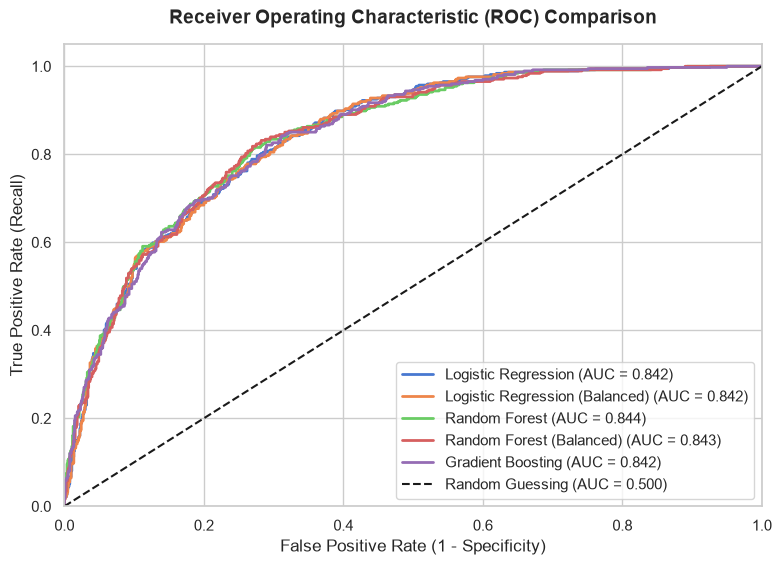

In [15]:
# ROC Curve Comparison
plt.figure(figsize=(9, 6))
for name, model in trained_models.items():
    probs = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    score = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {score:.3f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guessing (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Comparison', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='lower right', frameon=True)
plt.show()

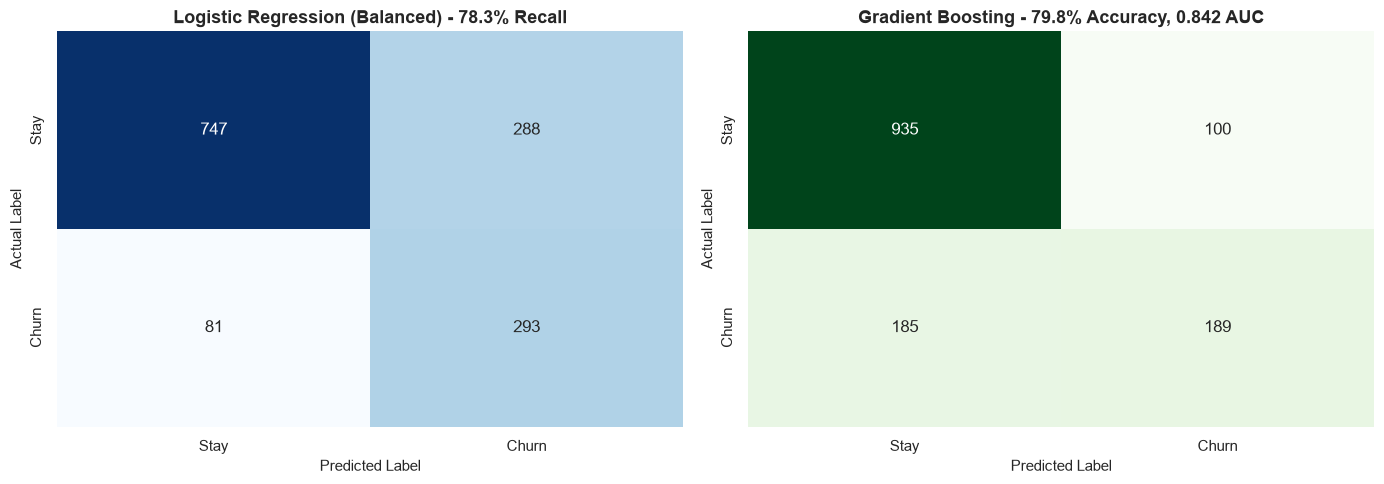

In [16]:
# Confusion Matrices Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Balanced (Recall Prioritized)
cm_lr = confusion_matrix(y_test, trained_models['Logistic Regression (Balanced)'].predict(X_test_scaled))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Stay', 'Churn'], yticklabels=['Stay', 'Churn'])
axes[0].set_title('Logistic Regression (Balanced) - 78.3% Recall', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('Actual Label', fontsize=11)

# Gradient Boosting (Overall Performance)
cm_gb = confusion_matrix(y_test, trained_models['Gradient Boosting'].predict(X_test_scaled))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Stay', 'Churn'], yticklabels=['Stay', 'Churn'])
axes[1].set_title('Gradient Boosting - 79.8% Accuracy, 0.842 AUC', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('Actual Label', fontsize=11)

plt.tight_layout()
plt.show()

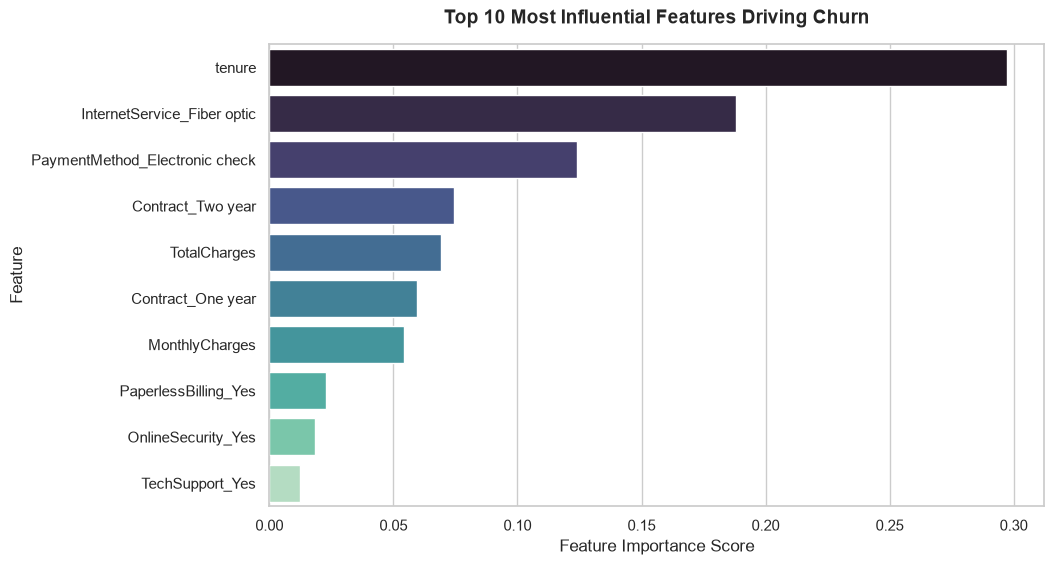

In [17]:
# Feature Importance Analysis (Gradient Boosting)
gb_model = trained_models['Gradient Boosting']
importances = gb_model.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(10), x='Importance', y='Feature', palette='mako')
plt.title('Top 10 Most Influential Features Driving Churn', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Feature Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

### 2. High-Risk Customer Prediction & Business Thresholding (>70%)

Rather than relying on an arbitrary 0.50 threshold, business retention teams require risk-tier segmentation:
* **High Risk (> 70% probability)**: Urgent retention intervention (dedicated agent call, aggressive 1-year contract discount, waiver of upgrade fees).
* **Moderate Risk (40% - 70% probability)**: Automated nurture (nudge campaigns, customer satisfaction surveys, feature discovery).
* **Low Risk (< 40% probability)**: Organic customer lifecycle.

Total Test Set Customers: 1,409
  - High Risk (>70%):     113 (8.0%)
  - Moderate Risk (40-70%):292 (20.7%)
  - Low Risk (<40%):      1004 (71.3%)


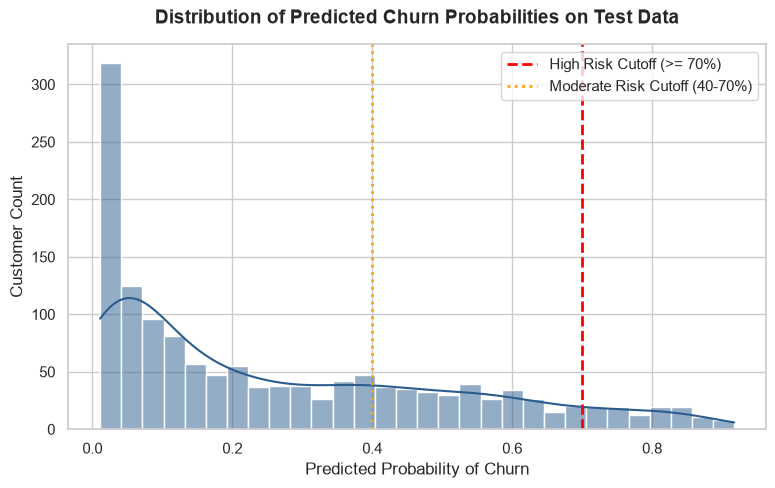

In [18]:
# High-Risk Customer Segmentation Analysis
gb_model = trained_models['Gradient Boosting']
test_probs = gb_model.predict_proba(X_test_scaled)[:, 1]

# Apply thresholding
high_risk_mask = test_probs >= 0.70
mod_risk_mask = (test_probs >= 0.40) & (test_probs < 0.70)
low_risk_mask = test_probs < 0.40

print(f"Total Test Set Customers: {len(test_probs):,}")
print(f"  - High Risk (>70%):     {high_risk_mask.sum():3d} ({high_risk_mask.mean():.1%})")
print(f"  - Moderate Risk (40-70%):{mod_risk_mask.sum():3d} ({mod_risk_mask.mean():.1%})")
print(f"  - Low Risk (<40%):      {low_risk_mask.sum():3d} ({low_risk_mask.mean():.1%})")

# Plot distribution with cutoffs
plt.figure(figsize=(9, 5))
sns.histplot(test_probs, bins=30, kde=True, color='#2b5c8f')
plt.axvline(0.70, color='red', linestyle='--', linewidth=2, label='High Risk Cutoff (>= 70%)')
plt.axvline(0.40, color='orange', linestyle=':', linewidth=2, label='Moderate Risk Cutoff (40-70%)')
plt.title('Distribution of Predicted Churn Probabilities on Test Data', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Probability of Churn', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
plt.legend(frameon=True)
plt.show()

## Phase 6: Final Artifacts & Production Export

We package and export:
1. The trained model (`Gradient Boosting` / `Logistic Regression Balanced`).
2. The fitted `StandardScaler`.
3. The engineered feature column schema.
4. Threshold metadata and configuration into `models/best_churn_model.pkl`.

In [19]:
# Export production model artifact bundle
os.makedirs(os.path.join('..', 'models'), exist_ok=True)
model_export_path = os.path.join('..', 'models', 'best_churn_model.pkl')
if not os.path.exists(os.path.dirname(model_export_path)):
    model_export_path = os.path.join('models', 'best_churn_model.pkl')

production_bundle = {
    'model_name': 'Gradient Boosting Classifier',
    'model': gb_model,
    'scaler': scaler,
    'feature_names': feature_names,
    'high_risk_threshold': 0.70,
    'moderate_risk_threshold': 0.40
}

joblib.dump(production_bundle, model_export_path)
print(f"Production bundle saved successfully to: {model_export_path}")

Production bundle saved successfully to: ..\models\best_churn_model.pkl


In [20]:
# Verify loading and sample inference
loaded_bundle = joblib.load(model_export_path)
sample_customer = X_test_scaled.iloc[[0]]
predicted_prob = loaded_bundle['model'].predict_proba(sample_customer)[0, 1]
risk_status = "High Risk (>70%)" if predicted_prob >= 0.70 else ("Moderate Risk" if predicted_prob >= 0.40 else "Low Risk")

print(f"Sample Customer Churn Probability: {predicted_prob:.2%}")
print(f"Assigned Risk Tier: {risk_status}")

Sample Customer Churn Probability: 1.97%
Assigned Risk Tier: Low Risk


## Strategic Business Recommendations
Based on our empirical analysis and model insights:
1. **Incentivize 1-Year and 2-Year Contracts:** Month-to-month contracts have a **42.7%** churn rate vs less than **11%** for long-term contracts. Offer introductory discounts or complimentary premium features for contract commitments.
2. **Fiber Optic Service Quality & Pricing Check:** Fiber optic users exhibited higher churn despite paying premium rates, indicating potential service reliability issues or price sensitivity.
3. **Target Early Tenure (First 12 Months):** Over **50%** of churn occurs within the first year. Implement an automated 30-day and 90-day onboarding check-in program.
4. **Transition from Electronic Checks:** Customers paying via electronic check have the highest churn. Offer a $2/month discount for setting up automated bank transfer or credit card billing.